First 5 Rows
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  

Last 5 Rows
      age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  \
1020   59    1   1       140   221    0        1      164      1      0.0   
1021   60    1   0       125   258    0        0      141      1      2.8   
1022   47    1   0       110   275    0        0      118      1      1.0   
1023   50    0   0       110   254    0        

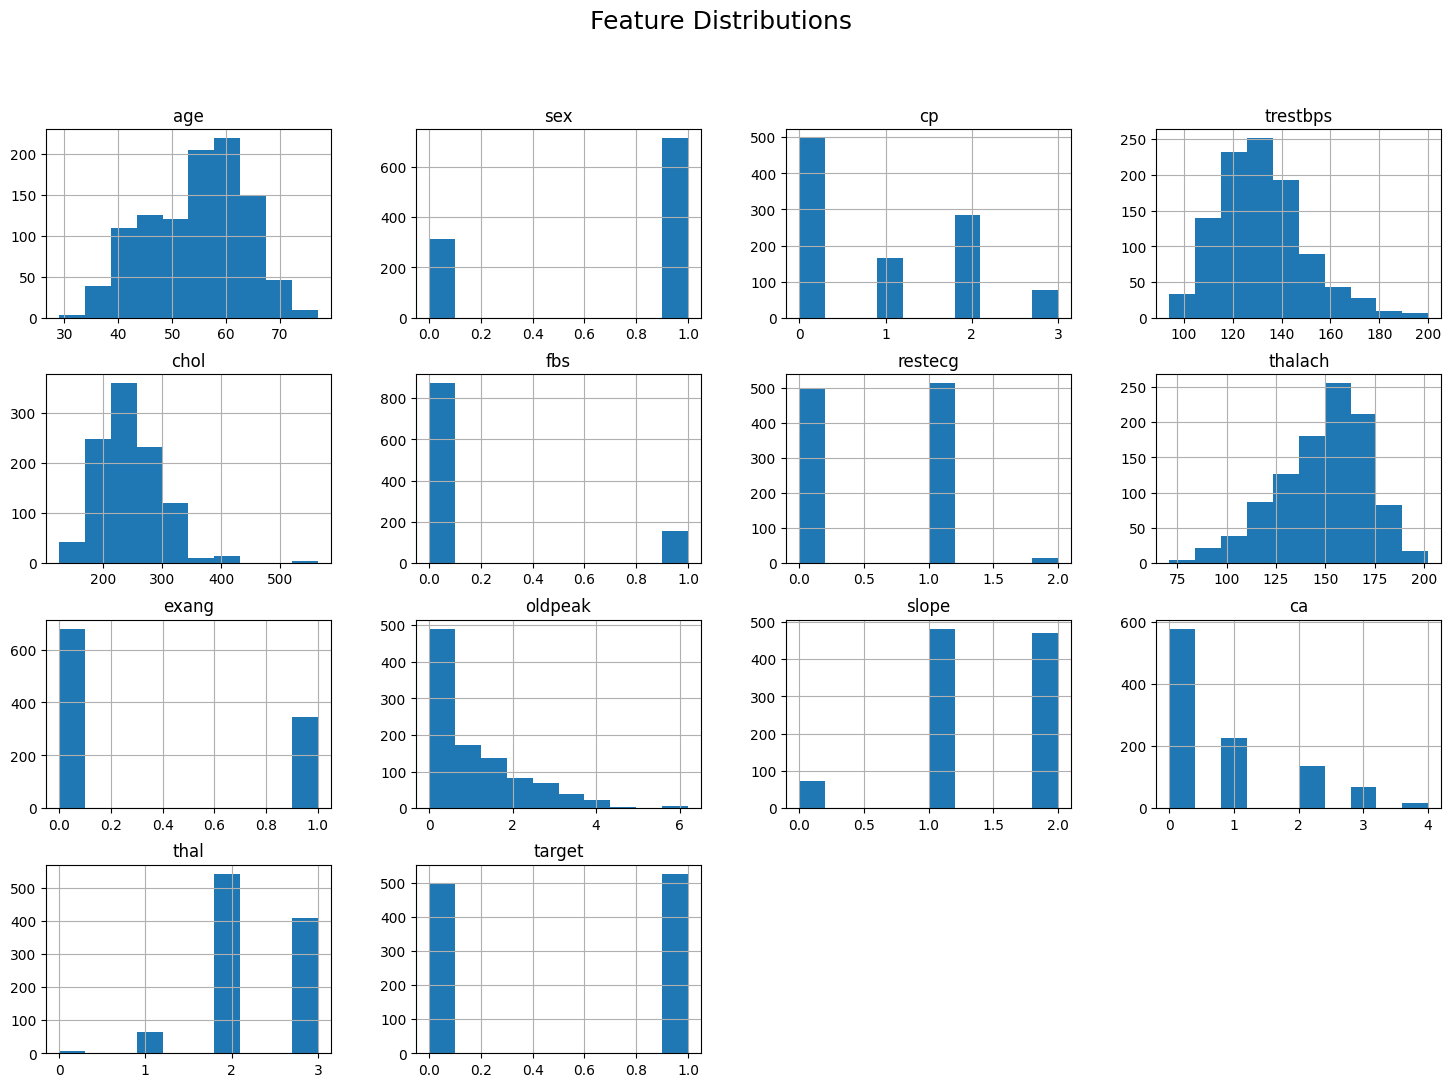

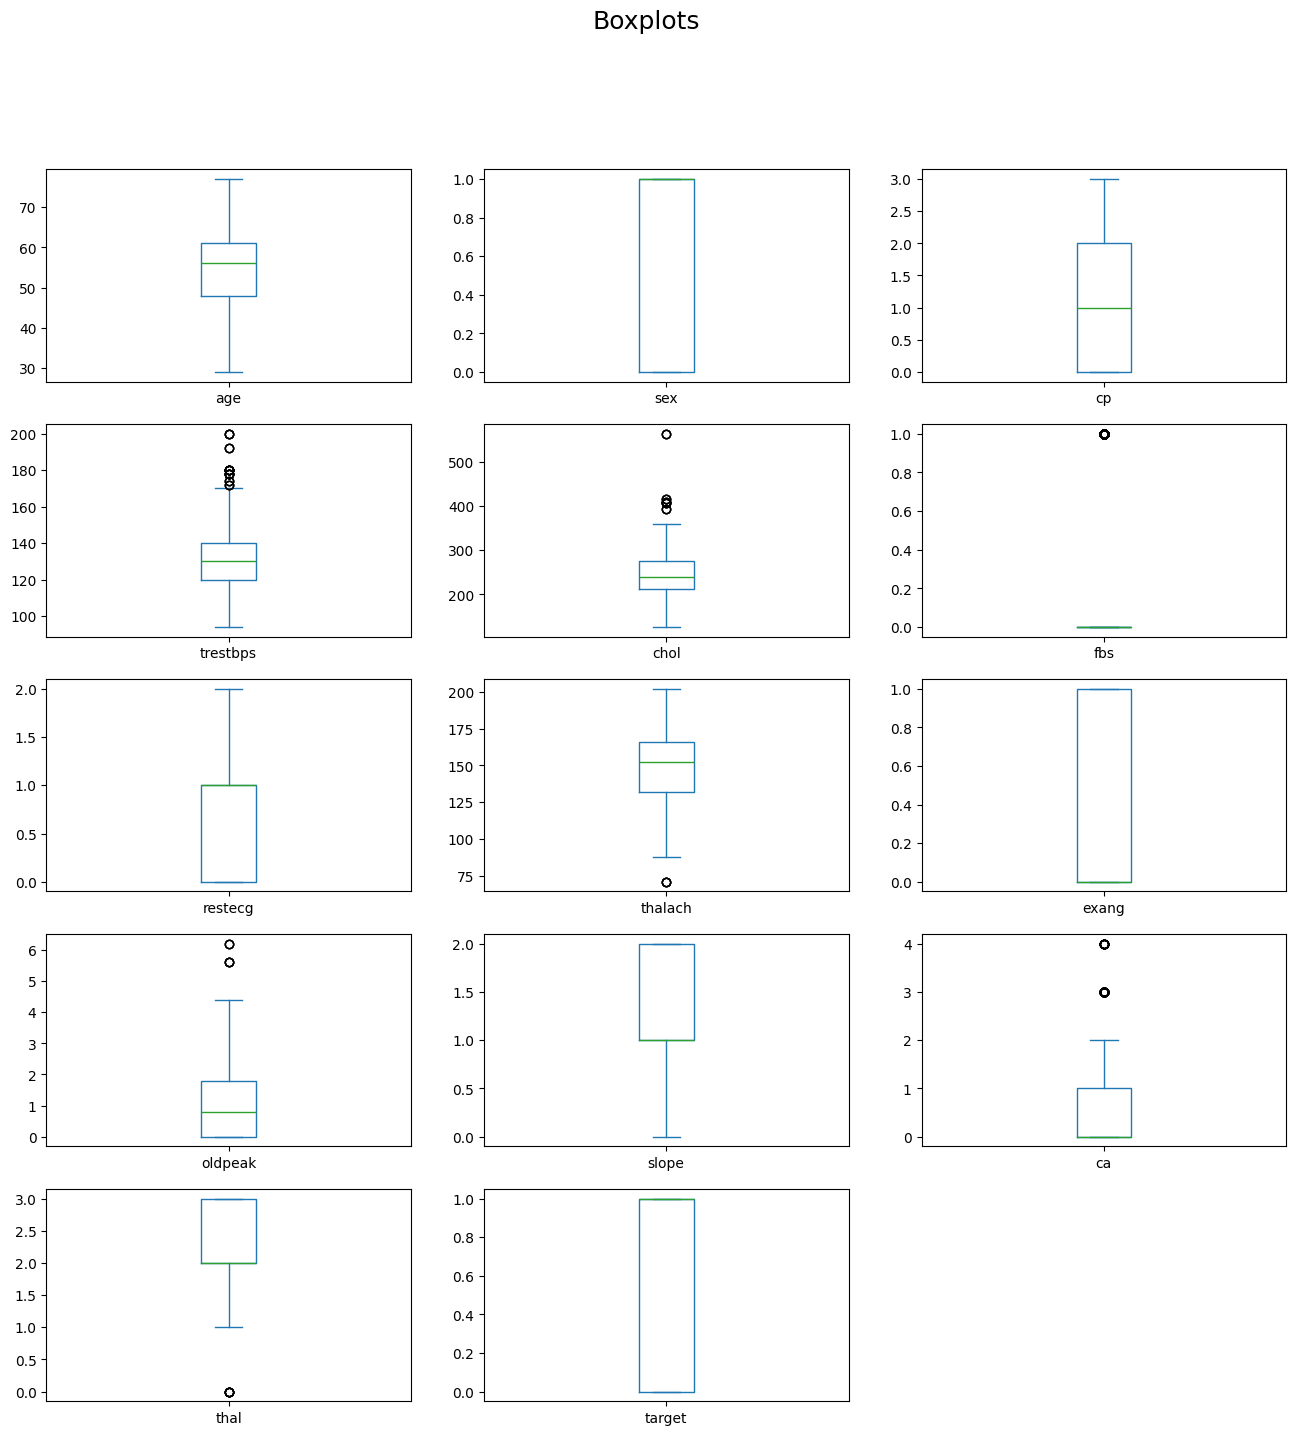

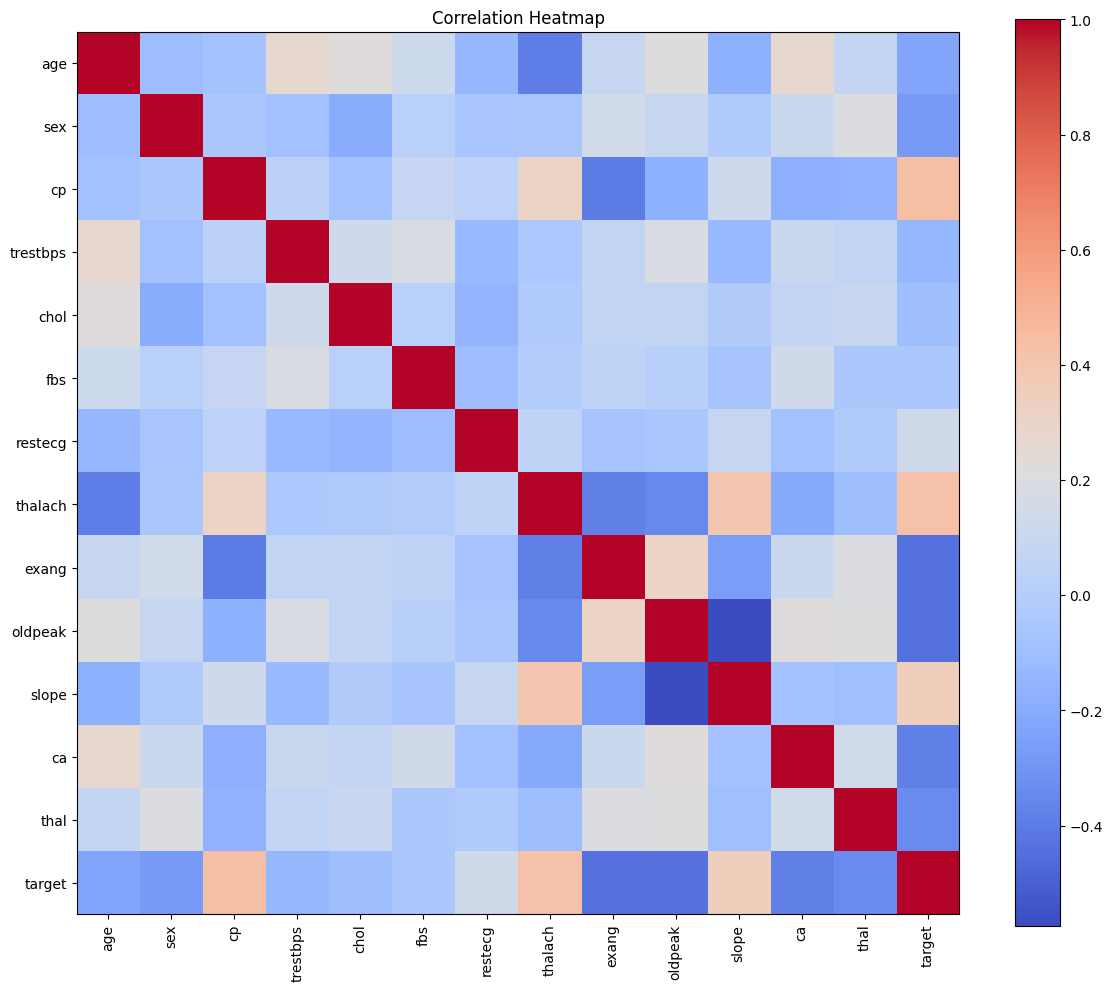

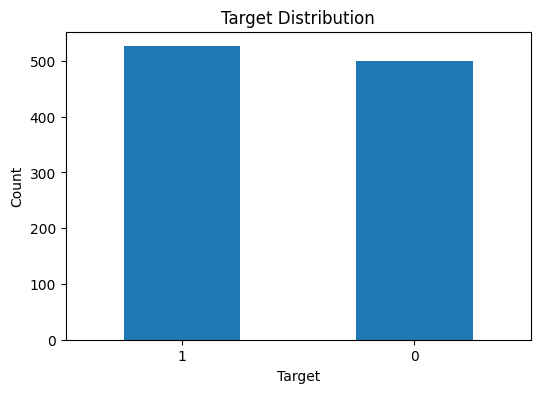

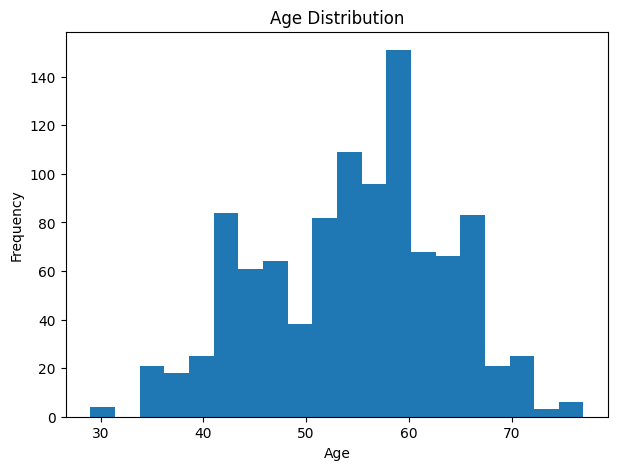

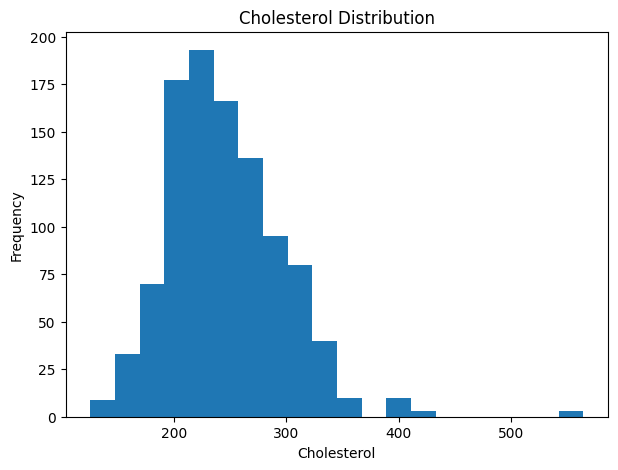

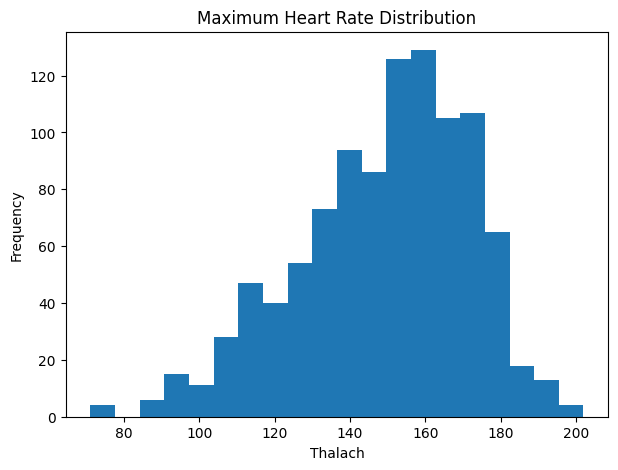


EDA Completed Successfully!


In [1]:
# ==============================
# Load Dataset & Complete EDA
# ==============================

# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# Load Dataset
df = pd.read_csv("/kaggle/input/datasets/johnsmith88/heart-disease-dataset/heart.csv")

# ------------------------------
# Basic Information
# ------------------------------
print("="*60)
print("First 5 Rows")
print("="*60)
print(df.head())

print("\n" + "="*60)
print("Last 5 Rows")
print("="*60)
print(df.tail())

print("\nDataset Shape:", df.shape)

print("\n" + "="*60)
print("Column Names")
print("="*60)
print(df.columns.tolist())

print("\n" + "="*60)
print("Dataset Information")
print("="*60)
print(df.info())

print("\n" + "="*60)
print("Statistical Summary")
print("="*60)
print(df.describe().T)

# ------------------------------
# Missing Values
# ------------------------------
print("\n" + "="*60)
print("Missing Values")
print("="*60)
print(df.isnull().sum())

# ------------------------------
# Duplicate Values
# ------------------------------
print("\nDuplicate Rows:", df.duplicated().sum())

# ------------------------------
# Data Types
# ------------------------------
print("\nData Types")
print(df.dtypes)

# ------------------------------
# Unique Values
# ------------------------------
print("\n" + "="*60)
print("Unique Values")
print("="*60)

for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")

# ------------------------------
# Target Distribution
# ------------------------------
print("\nTarget Value Counts")
print(df["target"].value_counts())

print("\nTarget Percentage")
print(df["target"].value_counts(normalize=True)*100)

# ==============================
# Visualization
# ==============================

# Histograms
df.hist(figsize=(18,12))
plt.suptitle("Feature Distributions", fontsize=18)
plt.show()

# Boxplots
df.plot(kind="box",
        subplots=True,
        layout=(5,3),
        figsize=(16,16),
        sharex=False,
        sharey=False)
plt.suptitle("Boxplots", fontsize=18)
plt.show()

# Correlation Heatmap
corr = df.corr()

fig, ax = plt.subplots(figsize=(12,10))
im = ax.imshow(corr, cmap="coolwarm")

ax.set_xticks(np.arange(len(corr.columns)))
ax.set_yticks(np.arange(len(corr.columns)))

ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticklabels(corr.columns)

plt.colorbar(im)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# Target Count Plot
plt.figure(figsize=(6,4))
df["target"].value_counts().plot(kind="bar")
plt.title("Target Distribution")
plt.xlabel("Target")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

# Age Distribution
plt.figure(figsize=(7,5))
plt.hist(df["age"], bins=20)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

# Cholesterol Distribution
plt.figure(figsize=(7,5))
plt.hist(df["chol"], bins=20)
plt.title("Cholesterol Distribution")
plt.xlabel("Cholesterol")
plt.ylabel("Frequency")
plt.show()

# Maximum Heart Rate Distribution
plt.figure(figsize=(7,5))
plt.hist(df["thalach"], bins=20)
plt.title("Maximum Heart Rate Distribution")
plt.xlabel("Thalach")
plt.ylabel("Frequency")
plt.show()

print("\nEDA Completed Successfully!")

In [2]:
# ==============================
# Data Preprocessing
# ==============================

# Import Libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load Dataset
df = pd.read_csv("/kaggle/input/datasets/johnsmith88/heart-disease-dataset/heart.csv")

# ------------------------------
# Check Missing Values
# ------------------------------
print("Missing Values:")
print(df.isnull().sum())

# ------------------------------
# Remove Duplicate Rows
# ------------------------------
duplicates = df.duplicated().sum()
print("\nDuplicate Rows:", duplicates)

if duplicates > 0:
    df = df.drop_duplicates()
    print("Duplicates Removed Successfully!")

# ------------------------------
# Define Features and Target
# ------------------------------
X = df.drop("target", axis=1)
y = df["target"]

# ------------------------------
# Train-Test Split
# ------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# ------------------------------
# Feature Scaling (Important for SVM)
# ------------------------------
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# ------------------------------
# Display Results
# ------------------------------
print("\nPreprocessing Completed Successfully!")
print("Training Features Shape :", X_train.shape)
print("Testing Features Shape  :", X_test.shape)
print("Training Labels Shape   :", y_train.shape)
print("Testing Labels Shape    :", y_test.shape)

Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Duplicate Rows: 723
Duplicates Removed Successfully!

Preprocessing Completed Successfully!
Training Features Shape : (241, 13)
Testing Features Shape  : (61, 13)
Training Labels Shape   : (241,)
Testing Labels Shape    : (61,)


In [3]:
# ==============================
# SVM Classification Model Training
# ==============================

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Create SVM Model
svm_model = SVC(
    kernel='rbf',      # You can also use 'linear', 'poly', or 'sigmoid'
    C=1.0,
    gamma='scale',
    random_state=42
)

# Train Model
svm_model.fit(X_train, y_train)

# Make Predictions
y_pred = svm_model.predict(X_test)

# Training Accuracy
train_accuracy = svm_model.score(X_train, y_train)

# Testing Accuracy
test_accuracy = accuracy_score(y_test, y_pred)

# Print Results
print("=" * 50)
print("SVM Classification Results")
print("=" * 50)
print(f"Training Accuracy : {train_accuracy:.4f}")
print(f"Testing Accuracy  : {test_accuracy:.4f}")
print("=" * 50)
print("Model Trained Successfully!")

SVM Classification Results
Training Accuracy : 0.9212
Testing Accuracy  : 0.7705
Model Trained Successfully!


SVM Classification Evaluation
Accuracy : 0.7705
Precision: 0.7714
Recall   : 0.8182
F1 Score : 0.7941

Classification Report
              precision    recall  f1-score   support

           0       0.77      0.71      0.74        28
           1       0.77      0.82      0.79        33

    accuracy                           0.77        61
   macro avg       0.77      0.77      0.77        61
weighted avg       0.77      0.77      0.77        61



<Figure size 600x500 with 0 Axes>

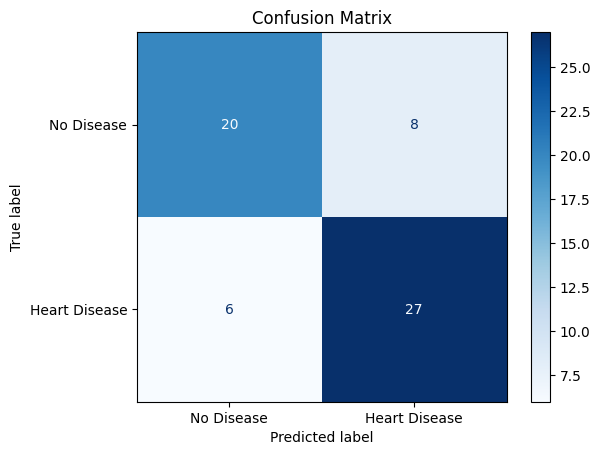

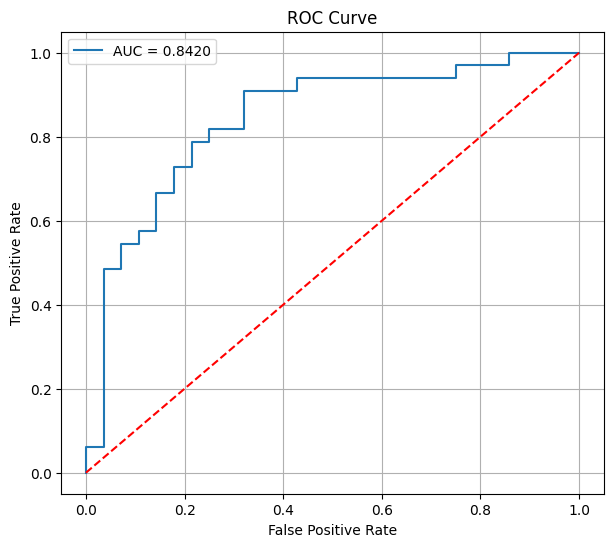

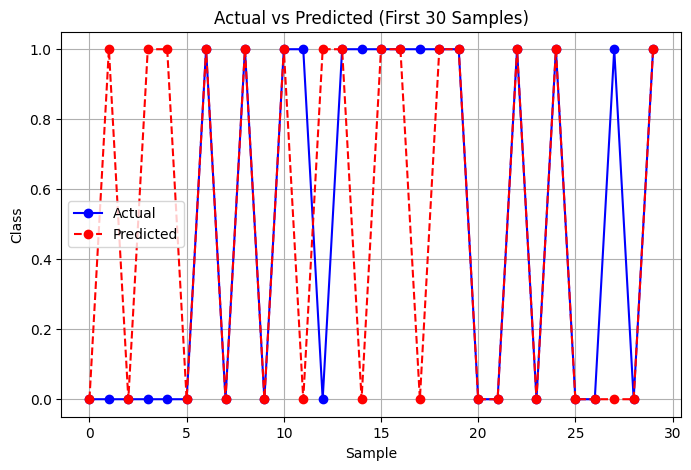

ROC-AUC Score : 0.8420


In [4]:
# ==============================
# SVM Evaluation & Visualization
# ==============================

import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    roc_auc_score
)

# ------------------------------
# Evaluation Metrics
# ------------------------------
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("="*50)
print("SVM Classification Evaluation")
print("="*50)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

print("\nClassification Report")
print("="*50)
print(classification_report(y_test, y_pred))

# ------------------------------
# Confusion Matrix
# ------------------------------
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=["No Disease","Heart Disease"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.grid(False)
plt.show()

# ------------------------------
# ROC Curve
# ------------------------------
y_prob = svm_model.decision_function(X_test)

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7,6))
plt.plot(fpr, tpr, label=f"AUC = {auc_score:.4f}")
plt.plot([0,1],[0,1],'r--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.show()

# ------------------------------
# Actual vs Predicted
# ------------------------------
plt.figure(figsize=(8,5))
plt.plot(y_test.values[:30], 'bo-', label='Actual')
plt.plot(y_pred[:30], 'ro--', label='Predicted')
plt.title("Actual vs Predicted (First 30 Samples)")
plt.xlabel("Sample")
plt.ylabel("Class")
plt.legend()
plt.grid(True)
plt.show()

print("="*50)
print(f"ROC-AUC Score : {auc_score:.4f}")
print("="*50)